<a href="https://colab.research.google.com/github/AbhinandLaji/Ai-Ml-lab/blob/main/AI_Cycle_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Q1. Load a dataset and display basic info
url = 'https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv'
df = pd.read_csv(url)

print("--- Basic Information ---")
df.info()

# Q2. Identify rows, columns, data types, and missing values
print(f"\nNumber of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")
print("\nMissing Values per Column (First 5):")
print(df.isnull().sum().head())

# Q3. Exploratory Data Inspection
print("\n--- First 3 Records ---")
display(df.head(3))
print("\n--- Last 3 Records ---")
display(df.tail(3))
print("\n--- Random 3 Records ---")
display(df.sample(3))

--- Basic Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0



--- Last 3 Records ---


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2



--- Random 3 Records ---


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1054,49,No,Travel_Rarely,1490,Research & Development,7,4,Life Sciences,1,1484,...,2,80,2,29,3,3,8,7,0,7
1442,29,Yes,Travel_Rarely,1092,Research & Development,1,4,Medical,1,2027,...,2,80,3,4,3,4,2,2,2,2
1212,34,No,Travel_Rarely,678,Research & Development,19,3,Life Sciences,1,1701,...,2,80,0,10,3,3,10,9,8,7


In [2]:
print("--- Q4: Handling Missing Values ---")
# Fill numerical missing values (MonthlyIncome) with the Median
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())

# Fill categorical missing values (Department) with the Mode (most frequent)
df['Department'] = df['Department'].fillna(df['Department'].mode()[0])

print("\n--- Q5: Handling Duplicates ---")
print(f"Duplicates found: {df.duplicated().sum()}")
df = df.drop_duplicates()
print("-" * 40)

print("\n--- Q13: Converting Data Types ---")
# Example: Convert MonthlyIncome from an integer to a float (decimal)
print(f"Data type of 'MonthlyIncome' BEFORE: {df['MonthlyIncome'].dtype}")
df['MonthlyIncome'] = df['MonthlyIncome'].astype(float)
print(f"Data type of 'MonthlyIncome' AFTER: {df['MonthlyIncome'].dtype}")
print("-" * 40)

print("\n--- Q14: Handling Inconsistent/Noisy Data ---")
print("BusinessTravel BEFORE cleaning:")
display(df[['BusinessTravel']].head(3))

# Clean text: remove dashes, strip accidental spaces, and convert to lowercase
df['BusinessTravel'] = df['BusinessTravel'].str.replace('-', ' ').str.strip().str.lower()

print("\nBusinessTravel AFTER cleaning:")
display(df[['BusinessTravel']].head(3))

--- Q4: Handling Missing Values ---

--- Q5: Handling Duplicates ---
Duplicates found: 0
----------------------------------------

--- Q13: Converting Data Types ---
Data type of 'MonthlyIncome' BEFORE: int64
Data type of 'MonthlyIncome' AFTER: float64
----------------------------------------

--- Q14: Handling Inconsistent/Noisy Data ---
BusinessTravel BEFORE cleaning:


,BusinessTravel
0,Travel_Rarely
1,Travel_Frequently
2,Travel_Rarely



BusinessTravel AFTER cleaning:


,BusinessTravel
0,travel_rarely
1,travel_frequently
2,travel_rarely


--- Q6 & Q7: Detecting and Handling Outliers ('MonthlyIncome') ---
Maximum MonthlyIncome BEFORE capping: 16581.0


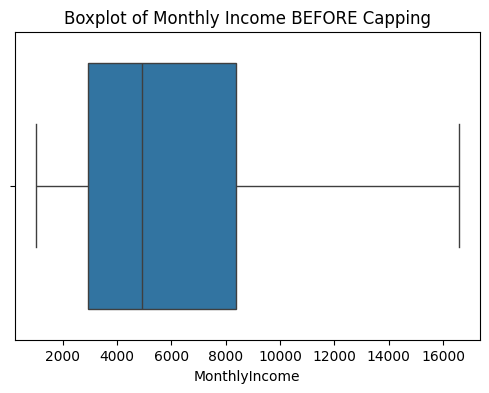


Maximum MonthlyIncome AFTER capping: 16581.0
----------------------------------------

--- Q12: Feature Engineering ---
New 'YearsPerCompany' feature created:


,TotalWorkingYears,NumCompaniesWorked,YearsPerCompany
0,8,8,0.987654
1,10,1,9.090909
2,7,6,1.147541
3,8,1,7.272727
4,6,9,0.659341


In [6]:
print("--- Q6 & Q7: Detecting and Handling Outliers ('MonthlyIncome') ---")
print(f"Maximum MonthlyIncome BEFORE capping: {df['MonthlyIncome'].max()}")

# Detect outliers using Box Plots
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['MonthlyIncome'])
plt.title("Boxplot of Monthly Income BEFORE Capping")
plt.show()

# Handle outliers using Statistical Methods (IQR Capping)
Q1 = df['MonthlyIncome'].quantile(0.25)
Q3 = df['MonthlyIncome'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

# Cap the extreme outliers at the upper limit to prevent skewed data
df['MonthlyIncome'] = np.where(df['MonthlyIncome'] > upper_limit, upper_limit, df['MonthlyIncome'])

print(f"\nMaximum MonthlyIncome AFTER capping: {df['MonthlyIncome'].max()}")
print("-" * 40)

print("\n--- Q12: Feature Engineering ---")
# Create a new feature: Average years spent at previous companies
# We add a tiny number (0.1) to prevent a "divide by zero" error for employees who haven't worked elsewhere.
df['YearsPerCompany'] = df['TotalWorkingYears'] / (df['NumCompaniesWorked'] + 0.1)

print("New 'YearsPerCompany' feature created:")
display(df[['TotalWorkingYears', 'NumCompaniesWorked', 'YearsPerCompany']].head(5))

In [7]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

print("--- Q8: Encoding Categorical Variables ---")
print("Data BEFORE Encoding:")
display(df[['Attrition', 'Department']].head(3))

# 1. Label Encoding (Best for binary categories like Attrition: Yes=1, No=0)
le = LabelEncoder()
df['Attrition'] = le.fit_transform(df['Attrition'])

# 2. One-Hot Encoding (Best for categories with no specific order, like 'Department')
df = pd.get_dummies(df, columns=['Department'], drop_first=True)

print("\nData AFTER Encoding:")
display(df.head(3))
print("-" * 40)

print("\n--- Q9: Feature Scaling ---")
# 1. Min-Max Normalization (Scales Age between 0 and 1)
min_max = MinMaxScaler()
df['Age_scaled'] = min_max.fit_transform(df[['Age']])

# 2. Standardization / Z-score (Scales MonthlyIncome to mean=0, std=1)
scaler = StandardScaler()
df['MonthlyIncome_scaled'] = scaler.fit_transform(df[['MonthlyIncome']])

print("Data AFTER Scaling (Comparing original to scaled):")
display(df[['Age', 'Age_scaled', 'MonthlyIncome', 'MonthlyIncome_scaled']].head(5))

--- Q8: Encoding Categorical Variables ---
Data BEFORE Encoding:


,Attrition,Department
0,Yes,Sales
1,No,Research & Development
2,Yes,Research & Development



Data AFTER Encoding:


,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,YearsPerCompany,Department_Research & Development,Department_Sales
0,41,1,travel_rarely,1102,1,2,Life Sciences,1,1,2,...,8,0,1,6,4,0,5,0.987654,False,True
1,49,0,travel_frequently,279,8,1,Life Sciences,1,2,3,...,10,3,3,10,7,1,7,9.090909,True,False
2,37,1,travel_rarely,1373,2,2,Other,1,4,4,...,7,3,3,0,0,0,0,1.147541,True,False


----------------------------------------

--- Q9: Feature Scaling ---
Data AFTER Scaling (Comparing original to scaled):


,Age,Age_scaled,MonthlyIncome,MonthlyIncome_scaled
0,41,0.547619,5993.0,-0.084766
1,49,0.738095,5130.0,-0.283072
2,37,0.452381,2090.0,-0.981623
3,33,0.357143,2909.0,-0.793428
4,27,0.214286,3468.0,-0.664977


--- Q17: Distribution of Numerical Features ---


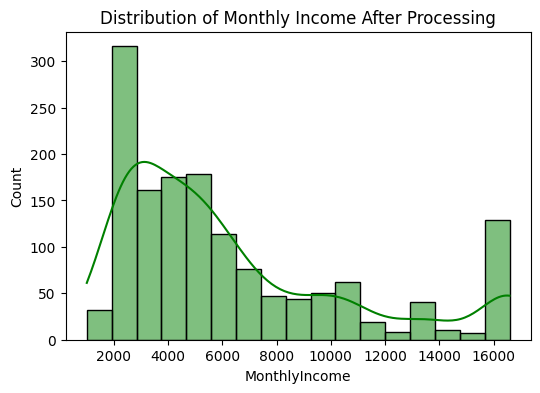

----------------------------------------

--- Q10 & Q11: Correlation Analysis ---
Correlation Matrix (Text Output):


,Attrition,Age,MonthlyIncome,JobSatisfaction,YearsAtCompany
Attrition,1.000000,-0.159205,-0.164778,-0.103481,-0.134392
Age,-0.159205,1.000000,0.499693,-0.004892,0.311309
MonthlyIncome,-0.164778,0.499693,1.000000,-0.007699,0.513556
JobSatisfaction,-0.103481,-0.004892,-0.007699,1.000000,-0.003803
YearsAtCompany,-0.134392,0.311309,0.513556,-0.003803,1.000000


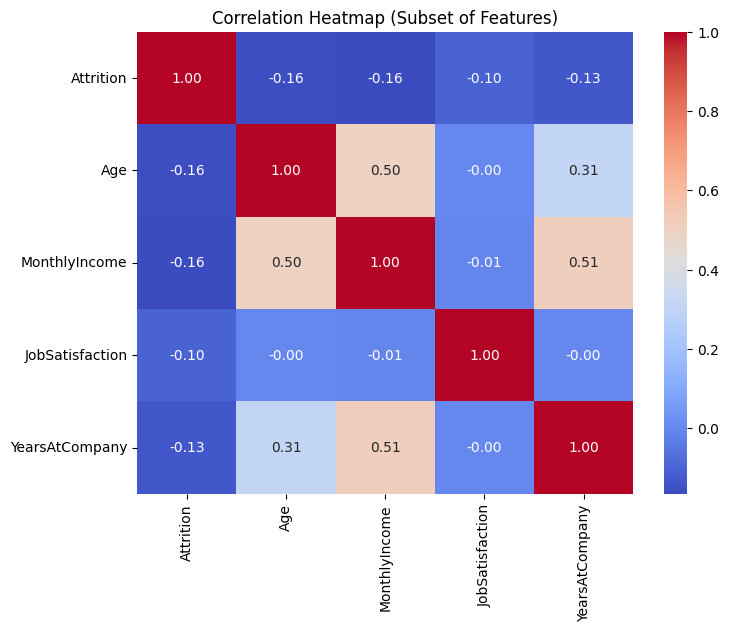

In [8]:
print("--- Q17: Distribution of Numerical Features ---")
plt.figure(figsize=(6, 4))
sns.histplot(df['MonthlyIncome'], kde=True, color='green')
plt.title("Distribution of Monthly Income After Processing")
plt.show()
print("-" * 40)

print("\n--- Q10 & Q11: Correlation Analysis ---")
# We only want to correlate numerical columns
numeric_df = df.select_dtypes(include=[np.number])

# To keep the heatmap readable, let's select a subset of interesting features
subset_features = ['Attrition', 'Age', 'MonthlyIncome', 'JobSatisfaction', 'YearsAtCompany']
correlation_matrix = numeric_df[subset_features].corr()

print("Correlation Matrix (Text Output):")
display(correlation_matrix)

# Generate Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap (Subset of Features)")
plt.show()

# Interpretation: Features with high negative correlation to 'Attrition' (like Age and MonthlyIncome)
# mean that as those metrics go up, the chance of an employee quitting goes down.

In [9]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# For simplicity before training, we will keep only the numeric columns for our final features
X = numeric_df.drop(columns=['Attrition'])
y = numeric_df['Attrition']

# Q15. Split dataset into training (80%) and testing sets (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Q16 & Q18. Compare dataset before and after balancing
print("--- Q16 & Q18: Splitting and Balancing Data ---")
print(f"Original Training Data Size (Before SMOTE): {X_train.shape[0]} rows")
print(f"Target variable ('Attrition') distribution BEFORE SMOTE:\n{y_train.value_counts()}\n")

# SMOTE generates synthetic data for the minority class (employees who left)
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f"Balanced Training Data Size (After SMOTE): {X_train_balanced.shape[0]} rows")
print(f"Target variable distribution AFTER SMOTE:\n{y_train_balanced.value_counts()}")
print("-" * 40)

# Q19. Save the cleaned and preprocessed dataset
print("\n--- Q19: Exporting Dataset ---")
cleaned_df = pd.concat([X, y], axis=1)
cleaned_df.to_csv('cleaned_employee_attrition.csv', index=False)
print("SUCCESS: Cleaned dataset saved as 'cleaned_employee_attrition.csv'!")
display(cleaned_df.head(3))

--- Q16 & Q18: Splitting and Balancing Data ---
Original Training Data Size (Before SMOTE): 1176 rows
Target variable ('Attrition') distribution BEFORE SMOTE:
Attrition
0    978
1    198
Name: count, dtype: int64

Balanced Training Data Size (After SMOTE): 1956 rows
Target variable distribution AFTER SMOTE:
Attrition
0    978
1    978
Name: count, dtype: int64
----------------------------------------

--- Q19: Exporting Dataset ---
SUCCESS: Cleaned dataset saved as 'cleaned_employee_attrition.csv'!


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,YearsPerCompany,Age_scaled,MonthlyIncome_scaled,Attrition
0,41,1102,1,2,1,1,2,94,3,2,...,0,1,6,4,0,5,0.987654,0.547619,-0.084766,1
1,49,279,8,1,1,2,3,61,2,2,...,3,3,10,7,1,7,9.090909,0.738095,-0.283072,0
2,37,1373,2,2,1,4,4,92,2,1,...,3,3,0,0,0,0,1.147541,0.452381,-0.981623,1
